<a href="https://colab.research.google.com/github/Lorenzo-v8/Clustering-de-clientes-de-un-centro-comercial-Mall-Customers-/blob/main/K_meansyDBSCAN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clustering de clientes de un centro comercial (Mall Customers)

**Objetivo:** segmentar a los clientes con K-means y DBSCAN, evaluando cada algoritmo sin PCA y con PCA, y analizar los grupos obtenidos.






**Pasos:**
1. Carga y exploración de los datos
2. Preprocesamiento (estandarización) y PCA
3. K-means: método del codo y silhouette para elegir *k*
4. DBSCAN: gráfico de k-distancias y búsqueda de `eps` y `min_samples`
5. Análisis (perfilado) de cada grupo
6. Comparación de resultados entre K-means y DBSCAN, con y sin PCA

#1_ Librerias

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2_ Carga de datos
Se carga el archivo `Mall_Customers.csv` (200 clientes). Las variables son `CustomerID`, `Gender`, `Age`, `Annual Income (k$)` y `Spending Score (1-100)`.

In [ ]:
try:
    from google.colab import files
    import os
    if not os.path.exists("Mall_Customers.csv"):
        files.upload()
except ImportError:
    pass

df = pd.read_csv("Mall_Customers.csv")
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


### 3_ Exploración inicial
Se revisan las dimensiones, los valores faltantes y las filas duplicadas. **Los duplicados se mantienen en el análisis**: no se elimina ninguna fila, por lo que los 200 clientes participan del clustering.

In [ ]:
print(df.shape)
print(df.isna().sum())
print(df.duplicated().sum(), "filas duplicadas")
df.describe(include="all")

(200, 5)
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64
0 filas duplicadas


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200,200.000000,200.000000,200.000000
unique,NaN,2,NaN,NaN,NaN
top,NaN,Female,NaN,NaN,NaN
freq,NaN,112,NaN,NaN,NaN
mean,100.500000,NaN,38.850000,60.560000,50.200000
std,57.879185,NaN,13.969007,26.264721,25.823522
min,1.000000,NaN,18.000000,15.000000,1.000000
25%,50.750000,NaN,28.750000,41.500000,34.750000
50%,100.500000,NaN,36.000000,61.500000,50.000000
75%,150.250000,NaN,49.000000,78.000000,73.000000


### 4_ Distribución de las variables
Histogramas de edad, ingreso anual y puntaje de gasto, y cantidad de clientes por género. El pairplot permite ver a simple vista la relación entre las variables y posibles agrupamientos naturales, sobre todo en el plano ingreso vs. gasto.

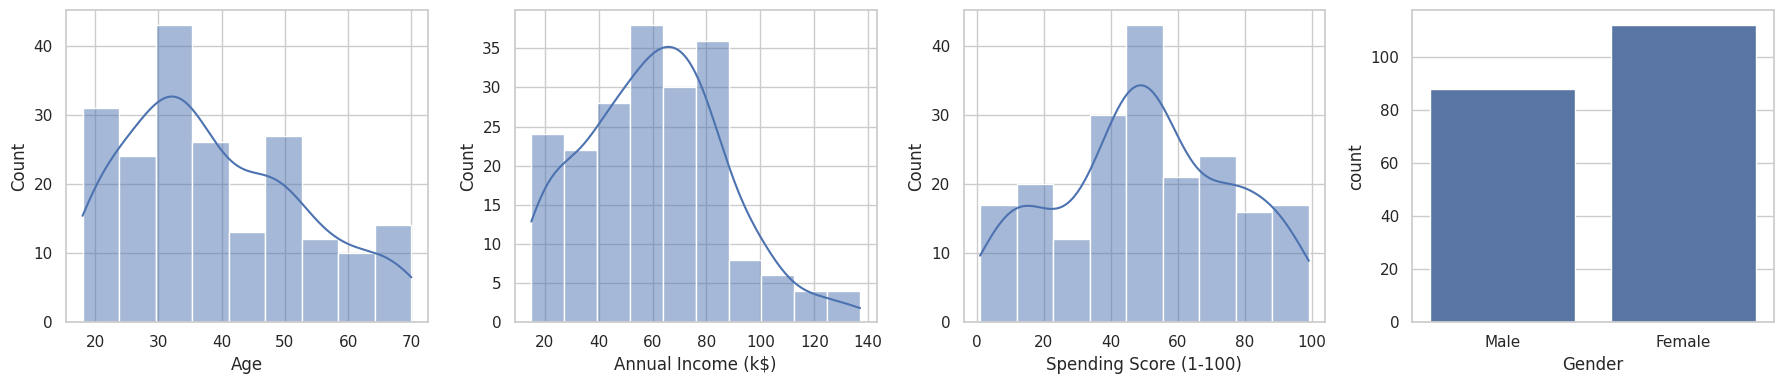

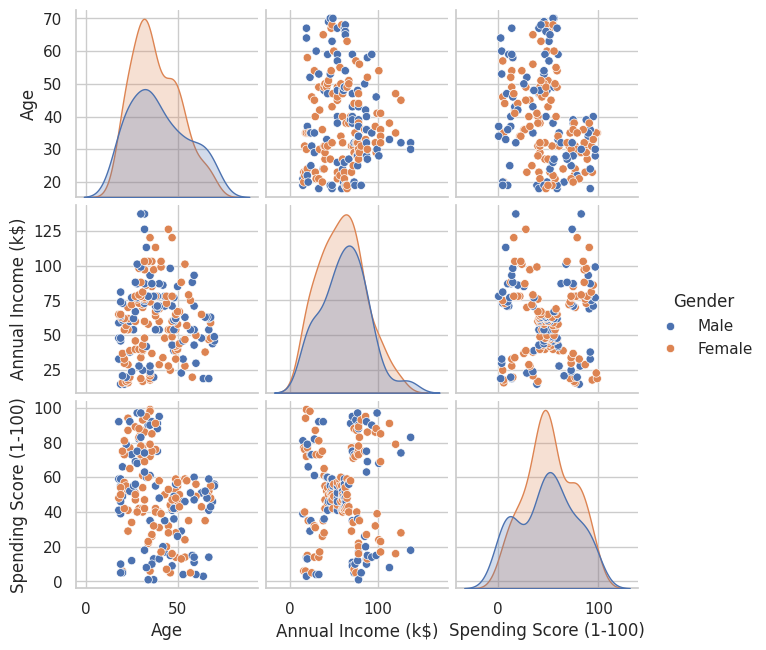

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
sns.histplot(df["Age"], kde=True, ax=axes[0])
sns.histplot(df["Annual Income (k$)"], kde=True, ax=axes[1])
sns.histplot(df["Spending Score (1-100)"], kde=True, ax=axes[2])
sns.countplot(x="Gender", data=df, ax=axes[3])
plt.tight_layout(); plt.show()

sns.pairplot(df.drop(columns="CustomerID"), hue="Gender", height=2.2)
plt.show()

##5_ Preprocesamiento y PCA
- `CustomerID` se descarta porque es solo un identificador.
- Las variables usadas para clusterizar son `Age`, `Annual Income (k$)` y `Spending Score (1-100)`. `Gender` es binaria y, al entrar en una distancia euclídea, tiende a separar los grupos por género de forma artificial; por eso **no se usa para clusterizar**, pero sí se utiliza después para **describir** los grupos.
- Se **estandarizan** las variables (K-means y DBSCAN se basan en distancias, por lo que la escala importa).
- **PCA:** con solo 3 variables, conservar todas las componentes sería únicamente una rotación de los ejes y daría resultados idénticos a no aplicar PCA. Por eso se retienen **2 componentes**, que explican alrededor del 77,6 % de la varianza.

Varianza explicada por componente: [0.443 0.333 0.224]
Varianza acumulada: [0.443 0.776 1.   ]

Componentes retenidos: 2 (varianza explicada: 77.6%)


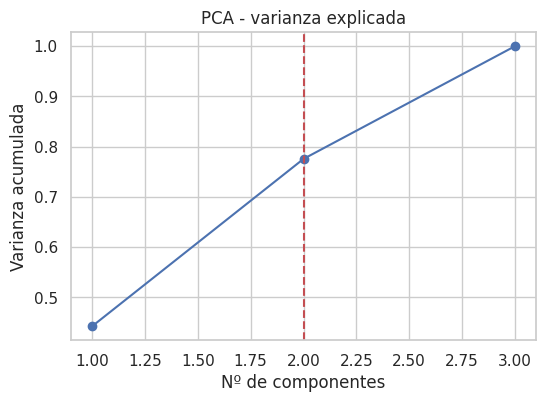

,Age,Annual Income (k$),Spending Score (1-100)
PC1,0.706,-0.048,-0.706
PC2,0.030,0.999,-0.038


In [ ]:
# Gender no se usa para clusterizar (es binaria y parte los grupos por género); sí se usa para perfilar
features = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
data = df[features].copy()

scaler = StandardScaler()
X = scaler.fit_transform(data)          # SIN PCA

pca_full = PCA(random_state=RANDOM_STATE).fit(X)
var_acum = np.cumsum(pca_full.explained_variance_ratio_)
print("Varianza explicada por componente:", np.round(pca_full.explained_variance_ratio_, 3))
print("Varianza acumulada:", np.round(var_acum, 3))

n_comp = 2
pca = PCA(n_components=n_comp, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)             # CON PCA
print(f"\nComponentes retenidos: {n_comp} (varianza explicada: {var_acum[n_comp-1]:.1%})")

X_vis = X_pca   # para graficar en 2D

plt.figure(figsize=(6, 4))
plt.plot(range(1, len(var_acum)+1), var_acum, "o-")
plt.axvline(n_comp, color="r", ls="--")
plt.xlabel("Nº de componentes"); plt.ylabel("Varianza acumulada")
plt.title("PCA - varianza explicada"); plt.show()

pd.DataFrame(pca.components_, columns=features,
             index=[f"PC{i+1}" for i in range(n_comp)]).round(3)

##6_ K-means
**Optimización del parámetro *k*:** se prueban valores de *k* entre 2 y 10 y se calculan:
- la **inercia** (método del codo): se busca el punto donde la mejora deja de ser significativa;
- el **coeficiente de silhouette**: mide qué tan bien separados y cohesivos están los grupos (más alto es mejor);
- el índice de **Davies-Bouldin** (más bajo es mejor).

Esto se hace tanto sin PCA como con PCA.

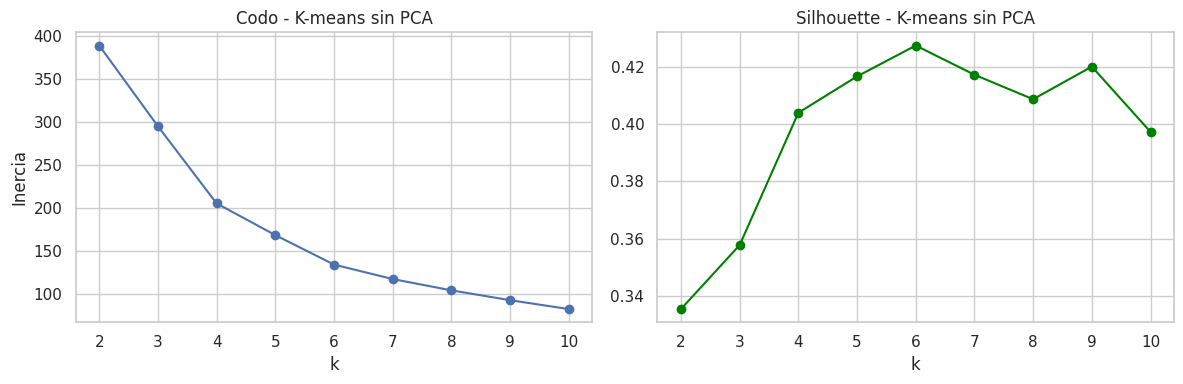

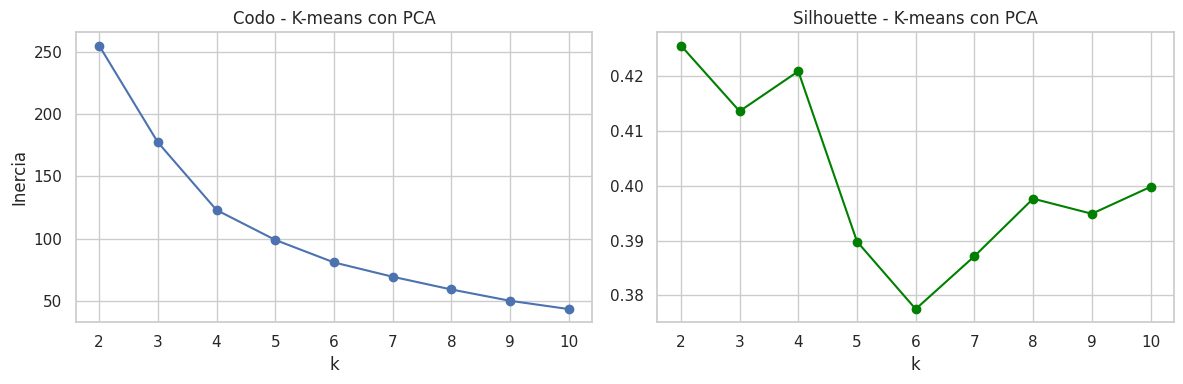

,k,inercia,silhouette,davies_bouldin
0,2,389.386,0.335,1.261
1,3,295.212,0.358,1.050
2,4,205.225,0.404,0.931
3,5,168.248,0.417,0.875
4,6,133.868,0.427,0.828
5,7,117.012,0.417,0.793
6,8,103.829,0.409,0.889
7,9,92.349,0.420,0.854
8,10,81.987,0.397,0.906


,k,inercia,silhouette,davies_bouldin
0,2,254.843,0.426,0.958
1,3,177.230,0.414,0.823
2,4,122.909,0.421,0.825
3,5,98.948,0.390,0.808
4,6,80.887,0.377,0.856
5,7,69.409,0.387,0.808
6,8,59.181,0.398,0.805
7,9,50.114,0.395,0.773
8,10,43.467,0.400,0.758


In [ ]:
def evaluar_kmeans(Xm, k_range=range(2, 11)):
    res = []
    for k in k_range:
        km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(Xm)
        res.append({"k": k, "inercia": km.inertia_,
                    "silhouette": silhouette_score(Xm, km.labels_),
                    "davies_bouldin": davies_bouldin_score(Xm, km.labels_)})
    return pd.DataFrame(res)

def grafico_codo(res, titulo):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(res["k"], res["inercia"], "o-"); ax[0].set_title(f"Codo - {titulo}")
    ax[0].set_xlabel("k"); ax[0].set_ylabel("Inercia")
    ax[1].plot(res["k"], res["silhouette"], "o-", color="green")
    ax[1].set_title(f"Silhouette - {titulo}"); ax[1].set_xlabel("k")
    plt.tight_layout(); plt.show()

res_km = evaluar_kmeans(X)
res_km_pca = evaluar_kmeans(X_pca)

grafico_codo(res_km, "K-means sin PCA")
grafico_codo(res_km_pca, "K-means con PCA")
display(res_km.round(3)); display(res_km_pca.round(3))

### 7_ Elección de *k* y ajuste final
Se elige el *k* con mayor silhouette, exigiendo al menos 3 grupos para que la segmentación sea útil desde el punto de vista del negocio. Esa elección se contrasta con el codo. Luego se ajusta el modelo final y se guardan las etiquetas de cada cliente.

In [ ]:
# k elegido por mejor silhouette (mínimo 3 grupos). Podés fijarlo a mano si el codo te convence más de otro valor
def elegir_k(res, k_min=3):
    r = res[res["k"] >= k_min]
    return int(r.loc[r["silhouette"].idxmax(), "k"])

K_SIN_PCA = elegir_k(res_km)
K_CON_PCA = elegir_k(res_km_pca)
# K_SIN_PCA = 5; K_CON_PCA = 5   # <- descomentar para forzar valores
print("k sin PCA:", K_SIN_PCA, "| k con PCA:", K_CON_PCA)

km_sin = KMeans(n_clusters=K_SIN_PCA, n_init=20, random_state=RANDOM_STATE).fit(X)
km_con = KMeans(n_clusters=K_CON_PCA, n_init=20, random_state=RANDOM_STATE).fit(X_pca)
df["KM_sinPCA"] = km_sin.labels_
df["KM_conPCA"] = km_con.labels_

k sin PCA: 6 | k con PCA: 4


## 8_ DBSCAN
DBSCAN tiene dos parámetros: `eps` (radio de vecindad) y `min_samples` (mínimo de puntos para formar una zona densa). Los puntos que no pertenecen a ninguna zona densa se marcan como **ruido** (etiqueta `-1`).

**Gráfico de k-distancias:** se ordena la distancia de cada punto a su *k*-ésimo vecino más cercano (con *k* = 2 × cantidad de dimensiones). El "codo" de la curva sugiere un valor razonable de `eps`.

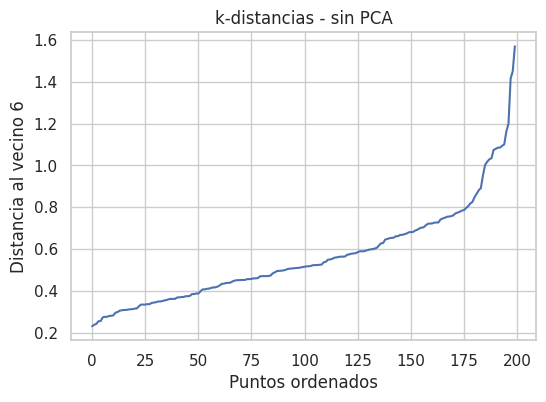

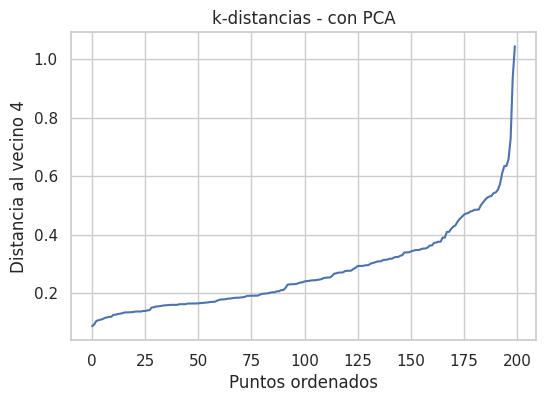

In [ ]:
def grafico_kdist(Xm, min_samples, titulo):
    nn = NearestNeighbors(n_neighbors=min_samples).fit(Xm)
    dist, _ = nn.kneighbors(Xm)
    kd = np.sort(dist[:, -1])
    plt.figure(figsize=(6, 4)); plt.plot(kd)
    plt.xlabel("Puntos ordenados"); plt.ylabel(f"Distancia al vecino {min_samples}")
    plt.title(f"k-distancias - {titulo}"); plt.show()

grafico_kdist(X, 2*X.shape[1], "sin PCA")
grafico_kdist(X_pca, 2*X_pca.shape[1], "con PCA")

### 9_ Búsqueda de `eps` y `min_samples`
Se recorre una grilla de combinaciones y se calcula el silhouette **sin contar los puntos de ruido**. Para que el resultado sea interpretable se exige que la combinación produzca entre 2 y 10 clusters y como máximo 15 % de ruido. Sin esas restricciones, el mejor silhouette aparece con muchísimos clusters diminutos, que no sirven para segmentar.

In [ ]:
def buscar_dbscan(Xm, eps_grid, ms_grid, max_ruido=0.15, max_clusters=10):
    filas = []
    for ms in ms_grid:
        for eps in eps_grid:
            lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(Xm)
            mask = lab != -1
            n_cl = len(set(lab[mask]))
            ruido = 1 - mask.mean()
            if n_cl >= 2 and mask.sum() > n_cl:
                sil = silhouette_score(Xm[mask], lab[mask])
            else:
                sil = np.nan
            filas.append({"eps": round(eps, 3), "min_samples": ms, "n_clusters": n_cl,
                          "ruido_%": round(100*ruido, 1), "silhouette": sil})
    r = pd.DataFrame(filas)
    validos = r[(r["n_clusters"].between(2, max_clusters)) & (r["ruido_%"] <= 100*max_ruido)].dropna(subset=["silhouette"])
    return r, validos.sort_values("silhouette", ascending=False)

eps_grid = np.arange(0.2, 1.6, 0.05)
ms_grid = range(3, 11)

grid_sin, top_sin = buscar_dbscan(X, eps_grid, ms_grid)
grid_con, top_con = buscar_dbscan(X_pca, eps_grid, ms_grid)

print("Mejores combinaciones SIN PCA"); display(top_sin.head(8).round(3))
print("Mejores combinaciones CON PCA"); display(top_con.head(8).round(3))

Mejores combinaciones SIN PCA


,eps,min_samples,n_clusters,ruido_%,silhouette
64,0.60,5,2,14.0,0.273
65,0.65,5,2,10.5,0.265
8,0.60,3,3,7.0,0.215
122,0.70,7,2,11.0,0.215
9,0.65,3,3,5.0,0.209
36,0.60,4,3,9.0,0.202
37,0.65,4,3,7.0,0.195
38,0.70,4,2,4.5,0.176


Mejores combinaciones CON PCA


,eps,min_samples,n_clusters,ruido_%,silhouette
202,0.50,10,2,15.0,0.371
60,0.40,5,2,14.5,0.368
174,0.50,9,2,14.0,0.366
89,0.45,6,2,13.5,0.363
31,0.35,4,2,15.0,0.363
203,0.55,10,2,11.5,0.353
5,0.45,3,3,3.5,0.172
32,0.40,4,2,9.0,0.073


###10_ Ajuste final de DBSCAN
Se ajusta DBSCAN con la mejor combinación encontrada para cada caso (sin PCA y con PCA). Los clientes con etiqueta `-1` son considerados ruido u outliers.

In [ ]:
best_sin = top_sin.iloc[0]; best_con = top_con.iloc[0]
# Para forzar valores a mano: best_sin = {"eps": 0.5, "min_samples": 5} etc.
print("DBSCAN sin PCA ->", dict(best_sin[["eps", "min_samples"]]))
print("DBSCAN con PCA ->", dict(best_con[["eps", "min_samples"]]))

db_sin = DBSCAN(eps=best_sin["eps"], min_samples=int(best_sin["min_samples"])).fit(X)
db_con = DBSCAN(eps=best_con["eps"], min_samples=int(best_con["min_samples"])).fit(X_pca)
df["DB_sinPCA"] = db_sin.labels_     # -1 = ruido / outlier
df["DB_conPCA"] = db_con.labels_

DBSCAN sin PCA -> {'eps': np.float64(0.6), 'min_samples': np.float64(5.0)}
DBSCAN con PCA -> {'eps': np.float64(0.5), 'min_samples': np.float64(10.0)}


###11_ Visualización y análisis de los grupos
Se grafican los cuatro resultados (K-means y DBSCAN, sin y con PCA). La fila superior muestra los clusters en el plano **ingreso anual vs. puntaje de gasto**; la inferior, en el plano de las **dos primeras componentes principales**.

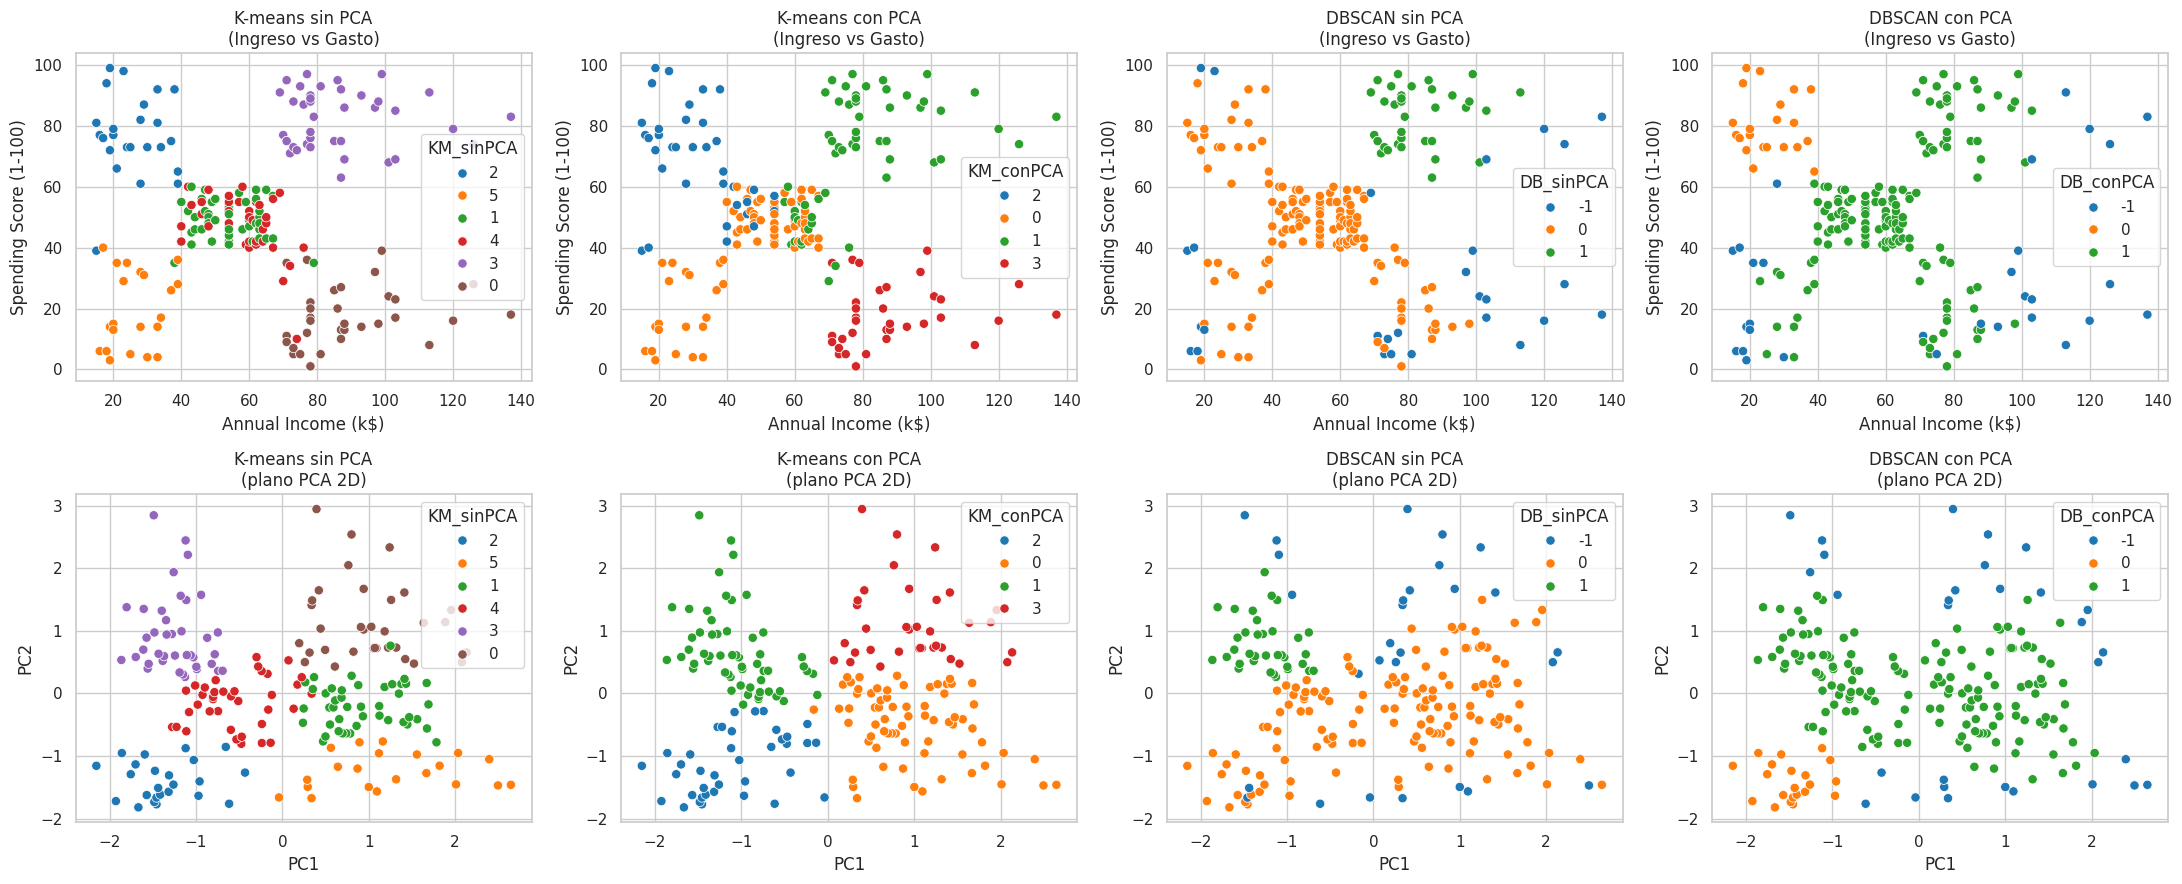

In [ ]:
modelos = {"KM_sinPCA": "K-means sin PCA", "KM_conPCA": "K-means con PCA",
           "DB_sinPCA": "DBSCAN sin PCA", "DB_conPCA": "DBSCAN con PCA"}

fig, axes = plt.subplots(2, 4, figsize=(22, 9))
for j, (col, nombre) in enumerate(modelos.items()):
    sns.scatterplot(x="Annual Income (k$)", y="Spending Score (1-100)", hue=df[col].astype(str),
                    palette="tab10", data=df, ax=axes[0, j], s=45)
    axes[0, j].set_title(nombre + "\n(Ingreso vs Gasto)")
    sns.scatterplot(x=X_vis[:, 0], y=X_vis[:, 1], hue=df[col].astype(str),
                    palette="tab10", ax=axes[1, j], s=45)
    axes[1, j].set_title(nombre + "\n(plano PCA 2D)")
    axes[1, j].set_xlabel("PC1"); axes[1, j].set_ylabel("PC2")
plt.tight_layout(); plt.show()

###12_ Perfil de cada grupo
Para cada cluster se calcula: cantidad de clientes, edad promedio, ingreso promedio, gasto promedio, porcentaje de mujeres y porcentaje sobre el total. Estas tablas son la base para describir e interpretar cada grupo. En DBSCAN, la fila `-1` corresponde al ruido.

In [ ]:
def perfil(col):
    g = df.groupby(col)
    t = g.agg(n=("Age", "size"),
              edad=("Age", "mean"),
              ingreso=("Annual Income (k$)", "mean"),
              gasto=("Spending Score (1-100)", "mean")).round(1)
    t["% mujeres"] = (g["Gender"].apply(lambda s: (s == "Female").mean()) * 100).round(1)
    t["% del total"] = (100 * t["n"] / len(df)).round(1)
    return t

for col, nombre in modelos.items():
    print(f"\n===== {nombre} =====  (en DBSCAN, -1 = ruido)")
    display(perfil(col))


===== K-means sin PCA =====  (en DBSCAN, -1 = ruido)


,n,edad,ingreso,gasto,% mujeres,% del total
KM_sinPCA,,,,,,
0,33,41.9,88.9,17.0,42.4,16.5
1,45,56.3,54.3,49.1,57.8,22.5
2,24,25.2,25.8,76.9,58.3,12.0
3,39,32.7,86.5,82.1,53.8,19.5
4,38,26.7,57.6,47.8,63.2,19.0
5,21,45.5,26.3,19.4,61.9,10.5



===== K-means con PCA =====  (en DBSCAN, -1 = ruido)


,n,edad,ingreso,gasto,% mujeres,% del total
KM_conPCA,,,,,,
0,69,52.1,46.3,40.1,58.0,34.5
1,58,30.0,79.1,70.8,58.6,29.0
2,38,25.6,32.6,67.5,60.5,19.0
3,35,41.7,88.2,17.3,42.9,17.5



===== DBSCAN sin PCA =====  (en DBSCAN, -1 = ruido)


,n,edad,ingreso,gasto,% mujeres,% del total
DB_sinPCA,,,,,,
-1,28,36.1,76.9,33.2,57.1,14.0
0,137,41.0,51.6,45.3,56.2,68.5
1,35,32.7,82.5,82.8,54.3,17.5



===== DBSCAN con PCA =====  (en DBSCAN, -1 = ruido)


,n,edad,ingreso,gasto,% mujeres,% del total
DB_conPCA,,,,,,
-1,30,42.0,72.4,30.6,53.3,15.0
0,21,24.8,25.6,80.2,61.9,10.5
1,149,40.2,63.1,49.9,55.7,74.5


###13_ Distribución de las variables por cluster
Los boxplots permiten ver la dispersión de edad, ingreso y gasto dentro de cada grupo, y qué tan diferenciados están entre sí.

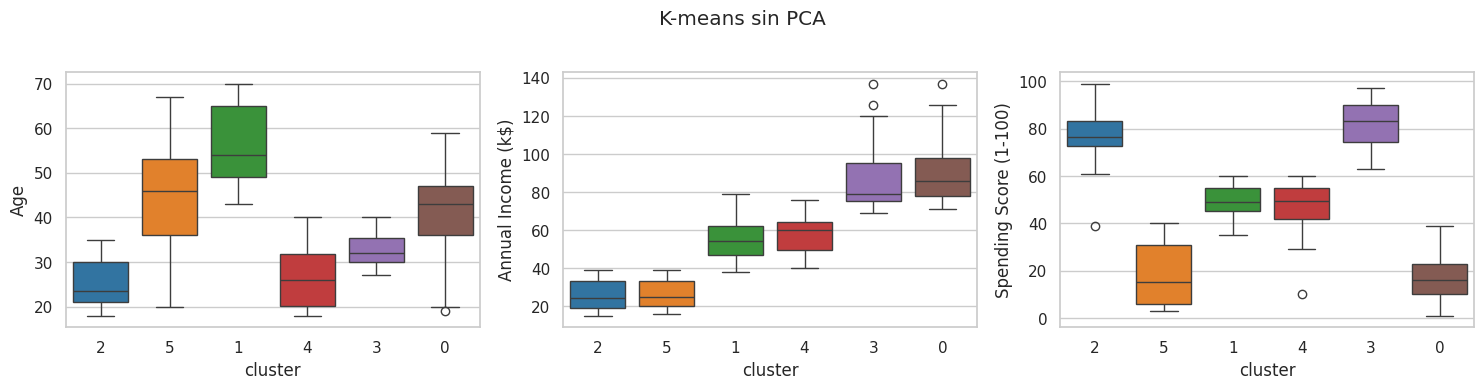

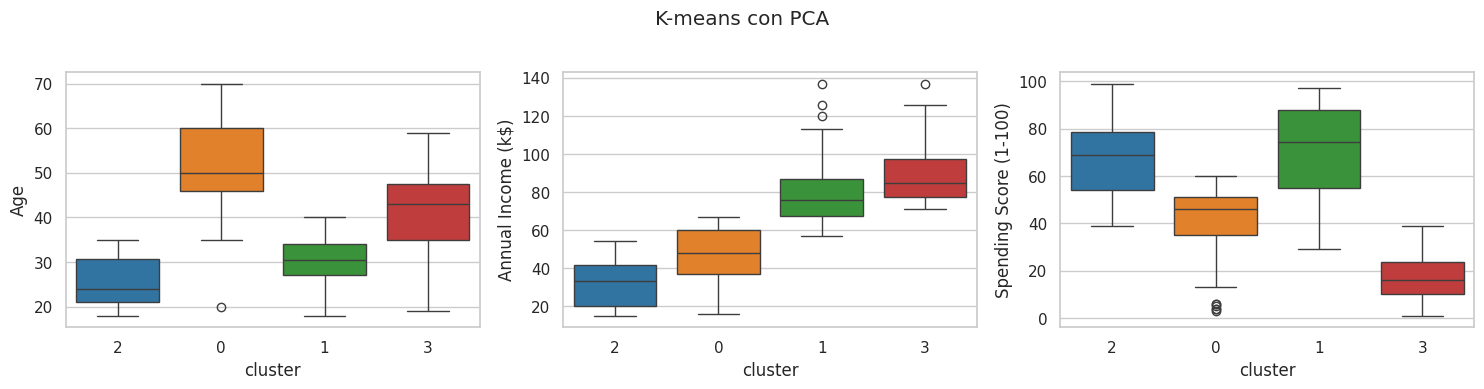

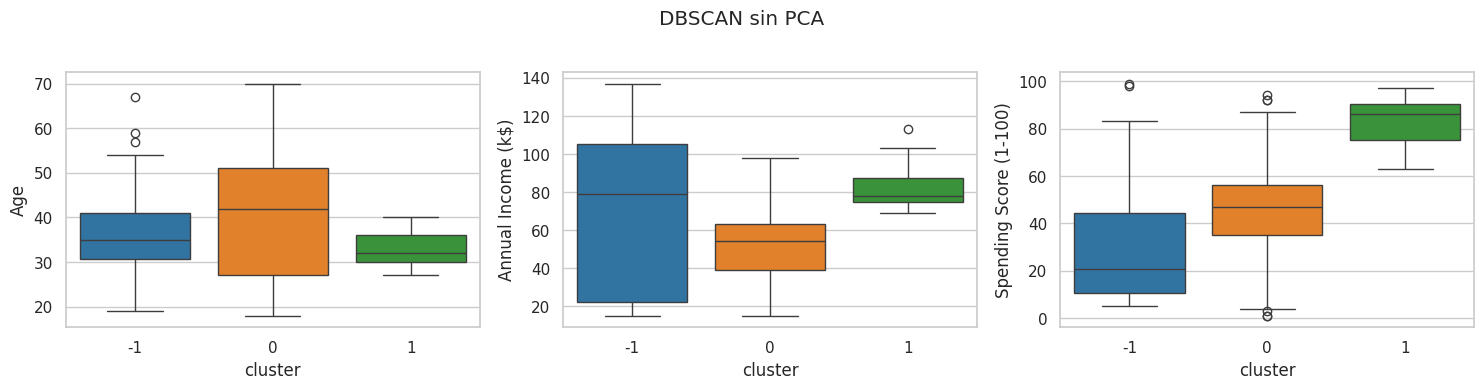

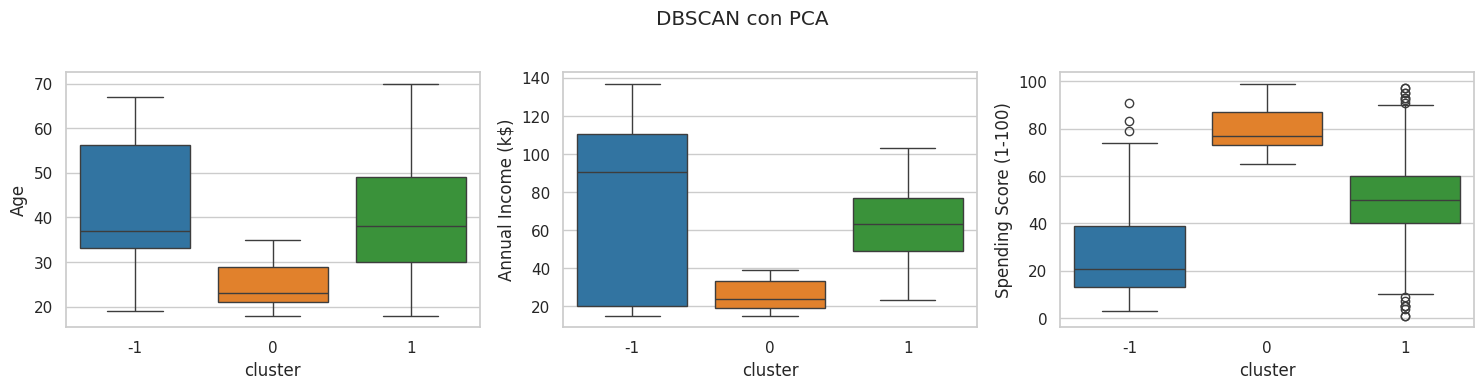

In [ ]:
for col, nombre in modelos.items():
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
    for ax, v in zip(axes, ["Age", "Annual Income (k$)", "Spending Score (1-100)"]):
        sns.boxplot(x=df[col].astype(str), y=df[v], hue=df[col].astype(str),
                    palette="tab10", legend=False, ax=ax)
        ax.set_xlabel("cluster")
    fig.suptitle(nombre, y=1.02); plt.tight_layout(); plt.show()

### Interpretación de los grupos

**K-means sin PCA (k = 6)**
- **Ingreso alto y gasto alto** (≈ 39 clientes, edad ≈ 33): clientes más valiosos, el público objetivo principal.
- **Ingreso alto y gasto bajo** (≈ 33 clientes, edad ≈ 42): tienen poder adquisitivo pero gastan poco; potencial de crecimiento con acciones de fidelización.
- **Ingreso bajo y gasto alto** (≈ 24 clientes, edad ≈ 25): jóvenes que gastan más de lo que ganan.
- **Ingreso bajo y gasto bajo** (≈ 21 clientes, edad ≈ 45): clientes poco activos.
- **Ingreso y gasto medios, mayores** (≈ 45 clientes, edad ≈ 56) y **ingreso y gasto medios, jóvenes** (≈ 38 clientes, edad ≈ 27): clientes estándar, diferenciados principalmente por la edad.

**K-means con PCA (k = 4)** agrupa de forma más gruesa: mayores con ingreso y gasto medios (≈ 69), jóvenes con ingreso y gasto altos (≈ 58), jóvenes con ingreso bajo y gasto alto (≈ 38) y adultos con ingreso alto y gasto bajo (≈ 35).

**DBSCAN** encuentra pocos grupos:
- Sin PCA: un cluster grande (≈ 137 clientes, perfil medio), un cluster de ingreso y gasto altos (≈ 35) y ≈ 14 % de ruido.
- Con PCA: un cluster grande (≈ 149), un cluster pequeño de jóvenes con ingreso bajo y gasto alto (≈ 21) y 15 % de ruido.
- El ruido está formado sobre todo por clientes de ingreso alto con gasto bajo o intermedio, que quedan en zonas de baja densidad.

**Género:** el porcentaje de mujeres ronda el 54–63 % en casi todos los grupos, por lo que `Gender` no es un factor que diferencie los segmentos.

##14_ Comparación de resultados
Se comparan los cuatro modelos con tres métricas internas: **silhouette** (mayor es mejor), **Davies-Bouldin** (menor es mejor) y **Calinski-Harabasz** (mayor es mejor). En DBSCAN las métricas se calculan **sin los puntos de ruido**, y se reporta aparte el porcentaje de ruido. Como los espacios (con y sin PCA) y la cantidad de clusters difieren, las métricas deben leerse como orientativas y no como una comparación estricta.

In [ ]:
espacios = {"KM_sinPCA": X, "KM_conPCA": X_pca, "DB_sinPCA": X, "DB_conPCA": X_pca}
filas = []
for col, nombre in modelos.items():
    lab = df[col].values; Xm = espacios[col]
    mask = lab != -1
    n_cl = len(set(lab[mask]))
    ok = n_cl >= 2
    filas.append({"Modelo": nombre, "Nº clusters": n_cl,
                  "% ruido": round(100 * (1 - mask.mean()), 1),
                  "Silhouette": silhouette_score(Xm[mask], lab[mask]) if ok else np.nan,
                  "Davies-Bouldin (menor=mejor)": davies_bouldin_score(Xm[mask], lab[mask]) if ok else np.nan,
                  "Calinski-Harabasz": calinski_harabasz_score(Xm[mask], lab[mask]) if ok else np.nan})
comparacion = pd.DataFrame(filas).set_index("Modelo").round(3)
display(comparacion)

,Nº clusters,% ruido,Silhouette,Davies-Bouldin (menor=mejor),Calinski-Harabasz
Modelo,,,,,
K-means sin PCA,6,0.0,0.427,0.828,135.102
K-means con PCA,4,0.0,0.421,0.825,182.080
DBSCAN sin PCA,2,14.0,0.273,1.020,54.421
DBSCAN con PCA,2,15.0,0.371,0.701,63.095


###15_ Concordancia entre particiones
El **Adjusted Rand Index (ARI)** mide qué tan parecidas son dos particiones: 1 indica que son idénticas y valores cercanos a 0 indican que no hay relación. Permite ver cuánto cambia el resultado al aplicar PCA y cuánto se parecen K-means y DBSCAN entre sí.

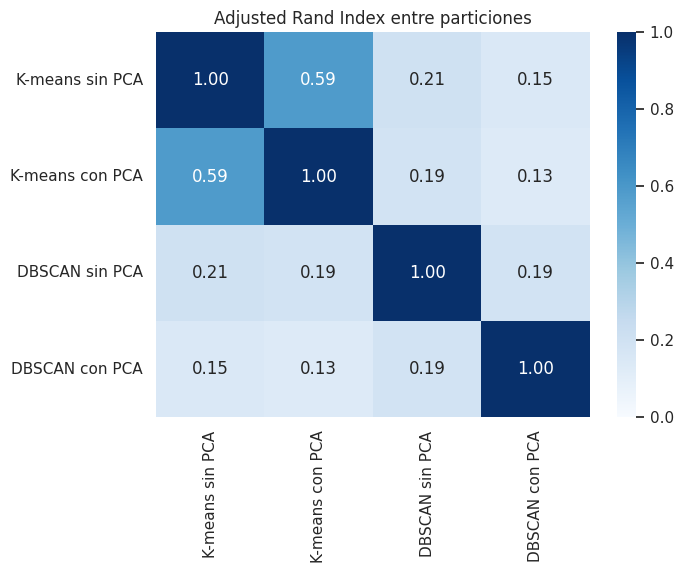

In [ ]:
cols = list(modelos.keys())
ari = pd.DataFrame(index=[modelos[c] for c in cols], columns=[modelos[c] for c in cols], dtype=float)
for a in cols:
    for b in cols:
        ari.loc[modelos[a], modelos[b]] = adjusted_rand_score(df[a], df[b])
plt.figure(figsize=(7, 5))
sns.heatmap(ari, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Adjusted Rand Index entre particiones"); plt.show()

###16_ Cómo se reparten los clusters de K-means dentro de los de DBSCAN
Las tablas cruzadas muestran, para cada cluster de K-means, a qué cluster de DBSCAN (o al ruido) pertenecen sus clientes. Sirven para ver qué grupos de K-means quedan "absorbidos" por el cluster grande de DBSCAN.

In [ ]:
display(pd.crosstab(df["KM_sinPCA"], df["DB_sinPCA"], rownames=["K-means"], colnames=["DBSCAN (-1=ruido)"]))
display(pd.crosstab(df["KM_conPCA"], df["DB_conPCA"], rownames=["K-means"], colnames=["DBSCAN (-1=ruido)"]))

DBSCAN (-1=ruido),-1,0,1
K-means,,,
0,14,19,0
1,0,45,0
2,3,21,0
3,4,0,35
4,2,36,0
5,5,16,0


DBSCAN (-1=ruido),-1,0,1
K-means,,,
0,9,0,60
1,5,0,53
2,3,21,14
3,13,0,22


## Conclusiones

- **K-means vs DBSCAN:** K-means asigna a todos los clientes a un grupo y permite segmentar con más detalle (6 grupos sin PCA), con mejores métricas internas y grupos fáciles de interpretar. DBSCAN no requiere fijar *k* y detecta outliers, pero en esta base solo identifica una zona densa grande y un grupo pequeño, porque los clientes forman nubes continuas sin separación clara por densidad. Además es sensible a `eps` y `min_samples`.
- **Con vs sin PCA:** con solo 3 variables, el PCA (2 componentes, ≈ 78 % de la varianza) reduce poco la dimensionalidad y pierde información, lo que se refleja en que K-means sugiere menos grupos (4 en lugar de 6). Además, las componentes son más difíciles de interpretar que las variables originales.
- **Comparación entre métodos:** K-means sin PCA es el que mejor segmenta para fines de negocio; DBSCAN resulta útil sobre todo para identificar clientes atípicos.
- **Recomendación de negocio:** priorizar al grupo de ingreso y gasto altos, diseñar acciones de fidelización para el grupo de ingreso alto y gasto bajo, y ofertas orientadas a jóvenes para el grupo de ingreso bajo y gasto alto.